# Engesgaard 1D: replacing one PHREEQC step with a random forest

Run `01_generate_data.py`, `02_train_models.py` and `04_profile_with_models.py` first. This notebook only reads their results.

**The problem.** In reactive transport, every time step has two parts: (a) *transport* moves the dissolved totals
(Ca, C, Cl, Mg) along the column, (b) *chemistry* lets PHREEQC bring every cell to equilibrium (calcite) or to its
kinetic rate (dolomite). Chemistry is called in every cell at every step, so it dominates the cost in large models.
The idea: learn the chemistry step with a model and call the model instead of PHREEQC.

**What is learned.** Input: the totals the cell receives, the calcite and dolomite it already has, and log10 of the
totals. Output: how much each species changes in that step, and the pH afterwards.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv("data/engesgaard_columns.csv")
res = np.load("results/test_predictions.npz", allow_pickle=True)
metrics = pd.read_csv("results/metrics.csv", index_col=0)
print(df.shape, "rows;", df.column.nunique(), "columns of", df.cell.nunique(), "cells and", df.step.nunique(), "steps")
df.head()

(44000, 16) rows; 11 columns of 100 cells and 40 steps


,column,step,cell,in_Ca,in_C,in_Cl,in_Mg,in_calcite,in_dolomite,out_Ca,out_C,out_Cl,out_Mg,out_calcite,out_dolomite,out_pH
0,0,0,0,0.000087,0.000087,5.874415e-04,2.937208e-04,0.000122,9.251520e-11,0.000135,0.000135,5.874415e-04,2.936827e-04,0.000074,3.811488e-08,9.882990
1,0,0,1,0.000120,0.000120,4.929822e-05,2.464911e-05,0.000122,9.251520e-11,0.000124,0.000124,4.929822e-05,2.464920e-05,0.000118,0.000000e+00,9.904695
2,0,0,2,0.000122,0.000122,4.137118e-06,2.068560e-06,0.000122,9.251520e-11,0.000123,0.000123,4.137118e-06,2.068652e-06,0.000122,0.000000e+00,9.906629
3,0,0,3,0.000123,0.000123,3.471888e-07,1.735949e-07,0.000122,9.251520e-11,0.000123,0.000123,3.471888e-07,1.736874e-07,0.000122,0.000000e+00,9.906792
4,0,0,4,0.000123,0.000123,2.913707e-08,1.456903e-08,0.000122,9.251520e-11,0.000123,0.000123,2.913707e-08,1.466155e-08,0.000122,0.000000e+00,9.906806


## 1. What the training data look like
Each training column is a different flow speed and dispersion. Inlet water (Mg and Cl, no Ca or C) enters at cell 0.
Calcite dissolves where it arrives, Ca and C go up, and dolomite precipitates slowly behind the calcite front.

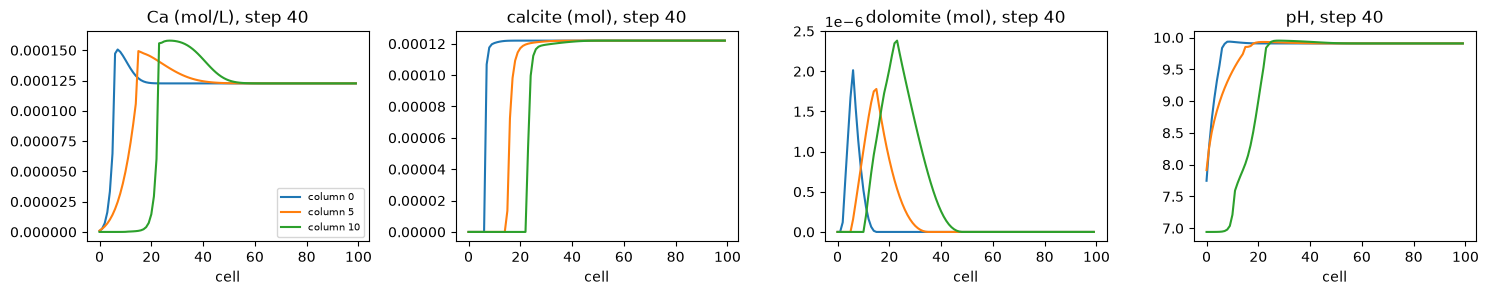

In [2]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for cc in (0, 5, 10):
    b = df[(df.column == cc) & (df.step == df.step.max())].sort_values("cell")
    for a, col in zip(ax, ["out_Ca", "out_calcite", "out_dolomite", "out_pH"]):
        a.plot(b.cell, b[col], label=f"column {cc}")
for a, t in zip(ax, ["Ca (mol/L)", "calcite (mol)", "dolomite (mol)", "pH"]): a.set_title(t + ", step 40"); a.set_xlabel("cell")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig("results/profiles.png", dpi=110); plt.show()

## 2. Accuracy on cells never seen in training
Each point is one cell at one step. Perfect prediction lies on the dashed line.
We plot the **change** over the step, not the final value: dolomite barely changes in one step, so the final value
is easy to get right (R² ≈ 0.99) even by predicting "no reaction". The change is the part chemistry really computes.

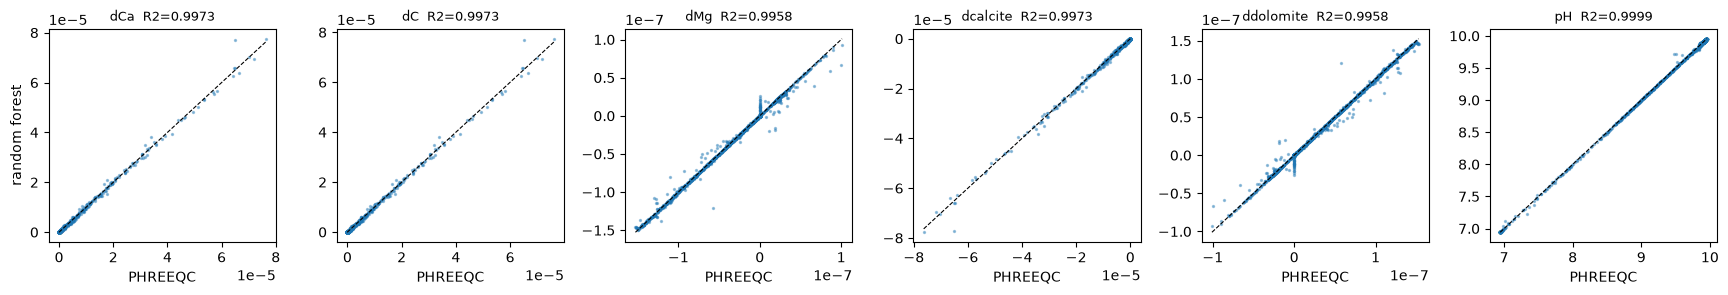

,RandomForest
fit_s,8.30000
predict_ms_per_cell,0.00367
R2_dCa,0.99730
R2_dC,0.99730
R2_dMg,0.99580
R2_dcalcite,0.99730
R2_ddolomite,0.99580
R2_pH,0.99990


In [3]:
y = res["y_true"]; targets = list(res["targets"]); p = res["RandomForest"]
fig, ax = plt.subplots(1, len(targets), figsize=(2.9 * len(targets), 3.2))
for j, t in enumerate(targets):
    ax[j].scatter(y[:, j], p[:, j], s=2, alpha=0.4)
    lo, hi = y[:, j].min(), y[:, j].max(); ax[j].plot([lo, hi], [lo, hi], "k--", lw=0.8)
    ax[j].set_title(f"{t}  R2={metrics.loc['RandomForest', 'R2_' + t]:.4f}", fontsize=9); ax[j].set_xlabel("PHREEQC")
ax[0].set_ylabel("random forest"); plt.tight_layout(); plt.savefig("results/parity.png", dpi=105); plt.show()
metrics.T

## 3. The harder test: the forest inside the transport loop
The Engesgaard benchmark column was never used for training. Here the chemistry of every cell and step is done by
the forest (`04_profile_with_models.py`). Errors accumulate over 40 steps, so a good R² on the test set is not enough.

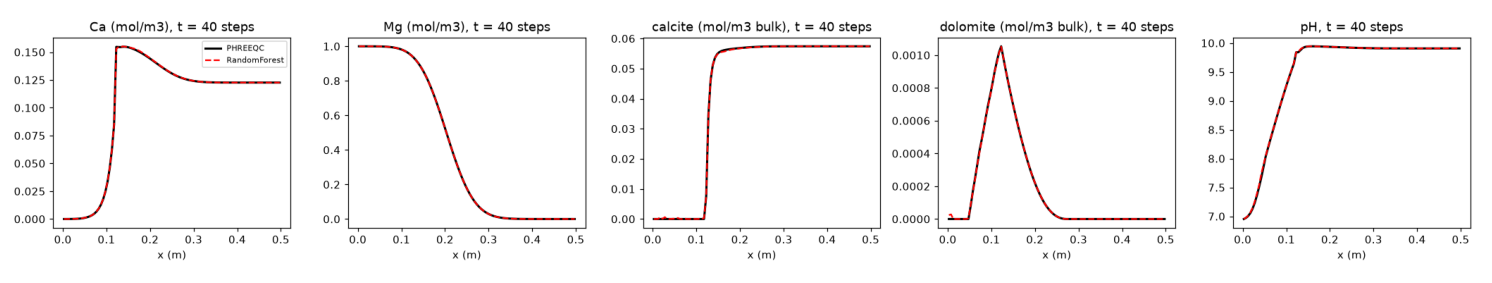

In [4]:
img = plt.imread("results/column_with_models.png")
plt.figure(figsize=(19, 3.6)); plt.imshow(img); plt.axis("off"); plt.show()

## 4. Things to try
- Remove the log10 columns from `common.py` and watch the pH profile in the inlet cells (x < 0.06 m) go flat.
- Change `COLUMNS` in `01_generate_data.py` (more or fewer speeds) and see which species get harder.
- Change the forest hyperparameters or run a `GridSearchCV`.
- Plot the error against the cell index: where does the forest make its largest errors?
- Cost: prediction time per cell is in `metrics.csv`; PHREEQC takes about 0.1 ms per cell in this case.